**Phase 3a - Concentration and hourly air-quality evaluation**

Estimate each reference gas from hour, weather and low-cost sensor only:
$$\hat{c}_g = \sum_{j} P(B_g = j \mid \text{hour, weather, sensors}) \cdot \bar{c}_{g,j}$$

Then apply a fixed threshold rule: an hour is bad when at least k of the four estimated gases exceed their thresholds.

**Evaulation principles**
* The discretizer, bin means, and dataset-relative threshold are learned from training split only.
* The Phase 2 network is fitted once per (bin count, seed) configuration and reused for all four gas queries
* References are never included in prediction evidence
* Validation selects (threshold family, k, bins, seed); the test set is evaluated only one cor the selected configuration.
* Results are saved under results/phase3a/; figurs under figures/phase3a/

In [1]:
%load_ext autoreload
%autoreload 2

import json
import math
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from cse250a.modules.config import config
from cse250a.modules.core import TIME_CARDS, Gas, Network, Sensor, Time, Weather
from cse250a.modules.data import Discretizer, blocked_split, load_air_quality
from cse250a.modules.eval.concentration import (
    bin_means,
    concentration_error,
    expected_concentration,
    resolution_floor,
)
from cse250a.modules.models import DiscreteBN, HourOnlyBaseline

SEEDS = (0, 1, 2)
BIN_COUNTS = (3, 5)
K_VALUES = (2, 3, 4)
GASES = (Gas.CO, Gas.C6H6, Gas.NOX, Gas.NO2)
SENSORS = tuple(Sensor)
WEATHER = (Weather.T, Weather.AH)
EVIDENCE = (Time.HOUR, *WEATHER, *SENSORS)
ALPHA = config.bins.alpha
RELATIVE_QUANTILE = 0.90

RESULT_DIR = config.paths.results_dir / "phase3a"
FIGURE_DIR = config.paths.figures_dir / "phase3a"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
print("Results:", RESULT_DIR)
print("Figures:", FIGURE_DIR)

Results: /workspaces/CSE-250A-Project/results/phase3a
Figures: /workspaces/CSE-250A-Project/figures/phase3a


**1. Load the data and define the Phase 2 network**
The Phase 2 edges are:
* S1 $\leftarrow$ CO
* S2 $\leftarrow$ C6H6
* S3 $\leftarrow$ NOx
* S4 $\leftarrow$ NO2, CO, NOx
* S5 $\leftarrow$ CO, NOx

Every gas has hour as its parent. Every sensor also has T and AH as parents.
Weather and hour are observed inputs; gas references are prediction targets, never evidence

In [19]:
raw = load_air_quality(config.paths.air_quality_csv)

# Phase 2 requires observed input variables. Do not drop rows just because a
# reference gas or a sensor is missing: the BN can handle missing observations.
before = len(raw)
raw = raw.dropna(subset=[Time.HOUR, *WEATHER]).copy()
print(f"Rows: {len(raw):,} (removed {before - len(raw):,} with missing hour/weather)")
print("Date range:", raw.index.min(), "to", raw.index.max())

GAS_PARENTS = {
    Sensor.S1: (Gas.CO,),
    Sensor.S2: (Gas.C6H6,),
    Sensor.S3: (Gas.NOX,),
    Sensor.S4: (Gas.NO2, Gas.CO, Gas.NOX),
    Sensor.S5: (Gas.CO, Gas.NOX),
}

def make_phase2_network(cards):
    structure = {g: (Time.HOUR,) for g in GASES}
    structure.update({
        sensor: (*GAS_PARENTS[sensor], *WEATHER)
        for sensor in SENSORS
    })
    return Network(structure=structure, cards=cards).validate()

# Quick data-availability check for the four reference gases.
availability = pd.DataFrame({
    "observed": raw[list(GASES)].notna().sum(),
    "missing": raw[list(GASES)].isna().sum(),
    "missing_pct": 100 * raw[list(GASES)].isna().mean(),
})
availability

Rows: 8,991 (removed 366 with missing hour/weather)
Date range: 2004-03-10 18:00:00 to 2005-04-04 14:00:00


,observed,missing,missing_pct
CO(GT),7344,1647,18.318318
C6H6(GT),8991,0,0.000000
NOx(GT),7396,1595,17.739962
NO2(GT),7393,1598,17.773329


**2. Threshold definitions**
Two threshold families are compared:

**1. Official-limit reference values.** The values below use the pollutant units in this dataset: CO in mg/m<sup>3</sup>, C6H6 and NO2 in $\mu\text{g/m}^3$ and NOx in ppb. The Nox value is an approximate conversion of 30 $\mu\text{g/m}^3$ as No2-equivalent to ppb at 25 degree Celsius. These standards have different adveraging periods (8-hour, annual, or hourly); applying them to single-hour observations is therefore an intentionally imperfect comparision, not a cliam of regulatory compliance.

**2. Dataset-relative values.** The 90th percentil of each gas in teh current training split. These provide an informative, comparable within-dataset definition of unusually high readings.

In [20]:
# Indicative EU limit / critical-level values mapped to the UCI dataset units.
# CO: 10 mg/m^3 (maximum daily 8-hour mean).
# C6H6: 5 ug/m^3 (annual mean).
# NO2: 200 ug/m^3 (1-hour limit value).
# NOx: 30 ug/m^3 as NO2-equivalent, approximately 16 ppb at 25 C.
OFFICIAL_THRESHOLDS = {
    Gas.CO: 10.0,
    Gas.C6H6: 5.0,
    Gas.NOX: 16.0,
    Gas.NO2: 200.0,
}

def thresholds_for(train_raw):
    relative = {
        gas: float(train_raw[gas].quantile(RELATIVE_QUANTILE))
        for gas in GASES
    }
    return {
        "official": OFFICIAL_THRESHOLDS.copy(),
        "relative": relative,
    }

def show_thresholds(thresholds):
    return pd.DataFrame(thresholds).rename_axis("gas")

preview_train_raw, _, _ = blocked_split(raw, seed=SEEDS[0])
show_thresholds(thresholds_for(preview_train_raw))

,official,relative
gas,,
CO(GT),10.0,4.0
C6H6(GT),5.0,19.9
NOx(GT),16.0,498.0
NO2(GT),200.0,174.0


**3. Helper functions**

air_quality returns 1 for bad and 0 for okay. It returns NaN if any of the four gas concentrations is missing. The metric helper reports the observed bad-hour prevalance and the confusion matrix as TN, FP, FN, TP, in addition to recall, precision, F1, and accuracy.

In [21]:
def air_quality(conc, thresholds, k=3):
    if not 1 <= k <= len(GASES):
        raise ValueError(f"k must be between 1 and {len(GASES)}")
    required = list(thresholds)
    if set(required) != set(GASES):
        raise ValueError("Thresholds must contain exactly the four modeled gases.")
    valid = conc[required].notna().all(axis=1)
    over = pd.DataFrame(
        {g: conc[g] > thresholds[g] for g in required},
        index=conc.index,
    )
    aq = (over.sum(axis=1) >= k).astype(float)
    return aq.where(valid).rename("AQ_bad")


def binary_metrics(y_true, y_pred):
    valid = y_true.notna() & y_pred.notna()
    yt = y_true.loc[valid].astype(int).to_numpy()
    yp = y_pred.loc[valid].astype(int).to_numpy()
    tn = int(((yt == 0) & (yp == 0)).sum())
    fp = int(((yt == 0) & (yp == 1)).sum())
    fn = int(((yt == 1) & (yp == 0)).sum())
    tp = int(((yt == 1) & (yp == 1)).sum())
    recall = tp / (tp + fn) if tp + fn else np.nan
    precision = tp / (tp + fp) if tp + fp else np.nan
    f1 = (
        2 * precision * recall / (precision + recall)
        if pd.notna(precision) and pd.notna(recall) and precision + recall
        else (0.0 if precision == 0 or recall == 0 else np.nan)
    )
    accuracy = (tp + tn) / len(yt) if len(yt) else np.nan
    return {
        "n": len(yt),
        "bad_rate": float(yt.mean()) if len(yt) else np.nan,
        "predicted_bad_rate": float(yp.mean()) if len(yp) else np.nan,
        "recall": recall,
        "precision": precision,
        "F1": f1,
        "accuracy": accuracy,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }


def estimate_all(model, binned, bin_means_by_gas):
    # One predict_proba call per gas for this already-fitted model.
    estimates = {}
    probabilities = {}
    for gas in GASES:
        proba = model.predict_proba(binned, gas, EVIDENCE)
        probabilities[gas] = proba
        estimates[gas] = expected_concentration(proba, bin_means_by_gas[gas])
    return pd.DataFrame(estimates, index=binned.index), probabilities


def make_bin_means(train_raw, train_binned):
    return {g: bin_means(train_raw[g], train_binned[g]) for g in GASES}

**4. Run the validation grid**
For each (bin, seed):
1. Make a blocked train/validation/test split
2. Fit the discretizer on **train only** using the four gases, five sensors, and weather columns.
3. Fit one Phase 2 BN and one hour-only baseline.
4. Predict each gas once per model and cache the resulting concentration estimates.
5. Score concentration MAE/RMSE and the AQ rule for both threshold families and $k \in {2, 3, 4}$.

In [5]:
concentration_rows = []
aq_rows = []
validation_cache = {}
model_cache = {}

for n_bins in BIN_COUNTS:
    for seed in SEEDS:
        train_raw, val_raw, test_raw = blocked_split(raw, seed=seed)

        discretizer = Discretizer(n_bins=n_bins).fit(
            train_raw, [*GASES, *SENSORS, *WEATHER]
        )
        train = discretizer.transform(train_raw)
        val = discretizer.transform(val_raw)
        test = discretizer.transform(test_raw)
        cards = {**discretizer.cards, **TIME_CARDS}

        network = make_phase2_network(cards)
        bn = DiscreteBN(network, alpha=ALPHA, seed=seed).fit(train)
        hour = HourOnlyBaseline(cards=cards, alpha=ALPHA).fit(train)

        c_bar = make_bin_means(train_raw, train)
        thresholds = thresholds_for(train_raw)

        # The slow inference calls happen here exactly once per (model, gas).
        bn_est, bn_proba = estimate_all(bn, val, c_bar)
        hour_est, hour_proba = estimate_all(hour, val, c_bar)

        validation_cache[(n_bins, seed)] = {
            "train_raw": train_raw, "val_raw": val_raw, "test_raw": test_raw,
            "train": train, "val": val, "test": test,
            "discretizer": discretizer, "cards": cards, "c_bar": c_bar,
            "thresholds": thresholds, "bn_est": bn_est, "hour_est": hour_est,
            "bn_proba": bn_proba, "hour_proba": hour_proba,
        }
        model_cache[(n_bins, seed)] = {"bn": bn, "hour": hour}

        # Persist every validation estimate so the slow posterior calls need not
        # be repeated merely to inspect results or build report tables.
        bn_est.to_csv(RESULT_DIR / f"estimates_bn_bins{n_bins}_seed{seed}_val.csv", index_label="datetime")
        hour_est.to_csv(RESULT_DIR / f"estimates_hour_bins{n_bins}_seed{seed}_val.csv", index_label="datetime")

        for gas in GASES:
            for model_name, estimates in (("BN", bn_est), ("HourOnlyBaseline", hour_est)):
                concentration_rows.append({
                    "bins": n_bins, "seed": seed, "gas": str(gas),
                    "model": model_name,
                    **concentration_error(estimates[gas], val_raw[gas]),
                })
            concentration_rows.append({
                "bins": n_bins, "seed": seed, "gas": str(gas),
                "model": "resolution_floor",
                **resolution_floor(val_raw[gas], val[gas], c_bar[gas]),
            })

        for threshold_name, threshold_values in thresholds.items():
            for k in K_VALUES:
                truth = air_quality(val_raw, threshold_values, k=k)
                for model_name, estimates in (("BN", bn_est), ("HourOnlyBaseline", hour_est)):
                    prediction = air_quality(estimates, threshold_values, k=k)
                    aq_rows.append({
                        "bins": n_bins, "seed": seed,
                        "threshold": threshold_name, "k": k,
                        "model": model_name,
                        **binary_metrics(truth, prediction),
                    })

        print(f"Finished bins={n_bins}, seed={seed}; "
              f"BN EM iterations={bn.result.n_iter if bn.result else 'n/a'}")

concentration_grid = pd.DataFrame(concentration_rows)
aq_grid = pd.DataFrame(aq_rows)
concentration_grid.to_csv(RESULT_DIR / "concentration_grid.csv", index=False)
aq_grid.to_csv(RESULT_DIR / "aq_grid.csv", index=False)
print("Saved validation grid tables.")

Finished bins=3, seed=0; BN EM iterations=5
Finished bins=3, seed=1; BN EM iterations=4
Finished bins=3, seed=2; BN EM iterations=4
Finished bins=5, seed=0; BN EM iterations=6
Finished bins=5, seed=1; BN EM iterations=5
Finished bins=5, seed=2; BN EM iterations=4
Saved validation grid tables.


**5. Per-gas concentration results**

Report the mean and standard deviation across the three blocked-split seeds. Every model is scored on observed validatioon reference readings. Compare the BN with the hour-only baseline and the resolution for each gas.

In [6]:
concentration_summary = (
    concentration_grid
    .groupby(["bins", "gas", "model"])
    .agg(
        n_mean=("n", "mean"),
        MAE_mean=("MAE", "mean"), MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"), RMSE_std=("RMSE", "std"),
    )
    .reset_index()
)
concentration_summary.round(4)

,bins,gas,model,n_mean,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,3,C6H6(GT),BN,2189.6667,2.3598,0.1194,3.7158,0.3125
1,3,C6H6(GT),HourOnlyBaseline,2189.6667,4.5265,0.2171,6.1014,0.3089
2,3,C6H6(GT),resolution_floor,2189.6667,2.3892,0.1101,3.7371,0.3004
3,3,CO(GT),BN,1853.0000,0.5436,0.0391,0.8068,0.0662
4,3,CO(GT),HourOnlyBaseline,1853.0000,0.8570,0.0391,1.1511,0.0356
5,3,CO(GT),resolution_floor,1853.0000,0.4608,0.0579,0.7058,0.0937
6,3,NO2(GT),BN,1854.6667,31.0509,2.6255,40.4246,3.8355
7,3,NO2(GT),HourOnlyBaseline,1854.6667,31.9767,2.8023,41.4433,3.9894
8,3,NO2(GT),resolution_floor,1854.6667,16.9806,1.7566,23.1349,3.5182
9,3,NOx(GT),BN,1855.0000,89.5126,1.3748,132.7053,11.2223


In [7]:
# Compact report-style table: MAE and RMSE shown as mean ± std.
concentration_report = concentration_summary.copy()
concentration_report["MAE (mean ± std)"] = concentration_report.apply(
    lambda r: f"{r.MAE_mean:.3f} ± {r.MAE_std:.3f}", axis=1
)
concentration_report["RMSE (mean ± std)"] = concentration_report.apply(
    lambda r: f"{r.RMSE_mean:.3f} ± {r.RMSE_std:.3f}", axis=1
)
concentration_report[["bins", "gas", "model", "n_mean", "MAE (mean ± std)", "RMSE (mean ± std)"]]

,bins,gas,model,n_mean,MAE (mean ± std),RMSE (mean ± std)
0,3,C6H6(GT),BN,2189.666667,2.360 ± 0.119,3.716 ± 0.313
1,3,C6H6(GT),HourOnlyBaseline,2189.666667,4.527 ± 0.217,6.101 ± 0.309
2,3,C6H6(GT),resolution_floor,2189.666667,2.389 ± 0.110,3.737 ± 0.300
3,3,CO(GT),BN,1853.000000,0.544 ± 0.039,0.807 ± 0.066
4,3,CO(GT),HourOnlyBaseline,1853.000000,0.857 ± 0.039,1.151 ± 0.036
5,3,CO(GT),resolution_floor,1853.000000,0.461 ± 0.058,0.706 ± 0.094
6,3,NO2(GT),BN,1854.666667,31.051 ± 2.626,40.425 ± 3.835
7,3,NO2(GT),HourOnlyBaseline,1854.666667,31.977 ± 2.802,41.443 ± 3.989
8,3,NO2(GT),resolution_floor,1854.666667,16.981 ± 1.757,23.135 ± 3.518
9,3,NOx(GT),BN,1855.000000,89.513 ± 1.375,132.705 ± 11.222


**6. AQ results and threshold informativeness**

For each threshold family and k, the reference AQ is computed from the four raw reference readings. Both the BN estimates and baseline estimates are passed through exactly the same rule. bad_rate is the frequency of bad hours in the reference labels; predicted_bad_rate is the frequency predicted by that model.

When official-limit bad hours are extremely rare, accuracy alone is misleading. Inspect bad_rate, recall, and precision first.

In [8]:
aq_summary = (
    aq_grid
    .groupby(["threshold", "k", "bins", "model"])
    .agg(
        n_mean=("n", "mean"),
        bad_rate_mean=("bad_rate", "mean"),
        bad_rate_std=("bad_rate", "std"),
        predicted_bad_rate_mean=("predicted_bad_rate", "mean"),
        recall_mean=("recall", "mean"), recall_std=("recall", "std"),
        precision_mean=("precision", "mean"), precision_std=("precision", "std"),
        F1_mean=("F1", "mean"), F1_std=("F1", "std"),
        accuracy_mean=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
    )
    .reset_index()
)
aq_summary.round(4)

,threshold,k,bins,model,n_mean,bad_rate_mean,bad_rate_std,predicted_bad_rate_mean,recall_mean,recall_std,precision_mean,precision_std,F1_mean,F1_std,accuracy_mean,accuracy_std
0,official,2,3,BN,1749.6667,0.7093,0.0338,0.6585,0.9243,0.0183,0.9962,0.0020,0.9588,0.0089,0.9441,0.0092
1,official,2,3,HourOnlyBaseline,1749.6667,0.7093,0.0338,0.8850,0.9696,0.0034,0.7771,0.0379,0.8624,0.0234,0.7811,0.0331
2,official,2,5,BN,1749.6667,0.7093,0.0338,0.8178,0.9928,0.0066,0.8607,0.0290,0.9218,0.0144,0.8809,0.0203
3,official,2,5,HourOnlyBaseline,1749.6667,0.7093,0.0338,0.8557,0.9535,0.0134,0.7910,0.0505,0.8638,0.0256,0.7870,0.0393
4,official,3,3,BN,1749.6667,0.0494,0.0172,0.0000,0.0000,0.0000,NaN,NaN,0.0000,0.0000,0.9506,0.0172
5,official,3,3,HourOnlyBaseline,1749.6667,0.0494,0.0172,0.0000,0.0000,0.0000,NaN,NaN,0.0000,0.0000,0.9506,0.0172
6,official,3,5,BN,1749.6667,0.0494,0.0172,0.0000,0.0000,0.0000,NaN,NaN,0.0000,0.0000,0.9506,0.0172
7,official,3,5,HourOnlyBaseline,1749.6667,0.0494,0.0172,0.0000,0.0000,0.0000,NaN,NaN,0.0000,0.0000,0.9506,0.0172
8,official,4,3,BN,1749.6667,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,1.0000,0.0000
9,official,4,3,HourOnlyBaseline,1749.6667,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,1.0000,0.0000


In [9]:
# Main comparison table, averaged over seeds, with all sensitivity dimensions visible.
aq_report = aq_summary.copy()
for metric in ("recall", "precision", "F1", "accuracy"):
    aq_report[f"{metric} (mean ± std)"] = aq_report.apply(
        lambda r: (
            f"{r[f'{metric}_mean']:.3f} ± {r[f'{metric}_std']:.3f}"
            if pd.notna(r[f"{metric}_mean"]) and pd.notna(r[f"{metric}_std"])
            else "n/a"
        ), axis=1
    )
aq_report[[
    "threshold", "k", "bins", "model", "n_mean", "bad_rate_mean",
    "recall (mean ± std)", "precision (mean ± std)",
    "F1 (mean ± std)", "accuracy (mean ± std)"
]]

,threshold,k,bins,model,n_mean,bad_rate_mean,recall (mean ± std),precision (mean ± std),F1 (mean ± std),accuracy (mean ± std)
0,official,2,3,BN,1749.666667,0.709259,0.924 ± 0.018,0.996 ± 0.002,0.959 ± 0.009,0.944 ± 0.009
1,official,2,3,HourOnlyBaseline,1749.666667,0.709259,0.970 ± 0.003,0.777 ± 0.038,0.862 ± 0.023,0.781 ± 0.033
2,official,2,5,BN,1749.666667,0.709259,0.993 ± 0.007,0.861 ± 0.029,0.922 ± 0.014,0.881 ± 0.020
3,official,2,5,HourOnlyBaseline,1749.666667,0.709259,0.953 ± 0.013,0.791 ± 0.050,0.864 ± 0.026,0.787 ± 0.039
4,official,3,3,BN,1749.666667,0.049393,0.000 ± 0.000,n/a,0.000 ± 0.000,0.951 ± 0.017
5,official,3,3,HourOnlyBaseline,1749.666667,0.049393,0.000 ± 0.000,n/a,0.000 ± 0.000,0.951 ± 0.017
6,official,3,5,BN,1749.666667,0.049393,0.000 ± 0.000,n/a,0.000 ± 0.000,0.951 ± 0.017
7,official,3,5,HourOnlyBaseline,1749.666667,0.049393,0.000 ± 0.000,n/a,0.000 ± 0.000,0.951 ± 0.017
8,official,4,3,BN,1749.666667,0.000000,n/a,n/a,n/a,1.000 ± 0.000
9,official,4,3,HourOnlyBaseline,1749.666667,0.000000,n/a,n/a,n/a,1.000 ± 0.000


**7. Select the configuration using validation only**

The default selection criterion is the highest mean validation F1 across seeds, comparing both threshold families, all k values, and both bin counts. The notebook selects the best (threshold family, k, bins) using the BN; the seed is then chosen as the median-performing seed for that configuration to avoid choosing a lucky split.

In [10]:
bn_only = aq_summary[aq_summary["model"] == "BN"].copy()
eligible = bn_only[bn_only["F1_mean"].notna()].copy()
if eligible.empty:
    raise RuntimeError(
        "No validation configuration has defined F1. Inspect reference AQ prevalence "
        "and threshold units before proceeding."
    )

best_row = eligible.sort_values(
    ["F1_mean", "recall_mean", "precision_mean"],
    ascending=False,
).iloc[0]
CHOSEN_THRESHOLD = str(best_row["threshold"])
CHOSEN_K = int(best_row["k"])
CHOSEN_BINS = int(best_row["bins"])

# Choose the seed whose BN F1 is closest to the three-seed mean for the chosen config.
seed_rows = aq_grid[
    (aq_grid["model"] == "BN")
    & (aq_grid["threshold"] == CHOSEN_THRESHOLD)
    & (aq_grid["k"] == CHOSEN_K)
    & (aq_grid["bins"] == CHOSEN_BINS)
]
target_f1 = seed_rows["F1"].mean()
CHOSEN_SEED = int(
    seed_rows.assign(distance=(seed_rows["F1"] - target_f1).abs())
    .sort_values("distance").iloc[0]["seed"]
)

chosen = validation_cache[(CHOSEN_BINS, CHOSEN_SEED)]
chosen_thresholds = chosen["thresholds"][CHOSEN_THRESHOLD]

print({
    "threshold_family": CHOSEN_THRESHOLD,
    "k": CHOSEN_K,
    "bins": CHOSEN_BINS,
    "representative_seed": CHOSEN_SEED,
    "validation_BN_F1_mean": float(best_row["F1_mean"]),
    "validation_BN_recall_mean": float(best_row["recall_mean"]),
    "validation_BN_precision_mean": float(best_row["precision_mean"]),
})
print("Chosen thresholds:", {str(g): v for g, v in chosen_thresholds.items()})

{'threshold_family': 'official', 'k': 2, 'bins': 3, 'representative_seed': 2, 'validation_BN_F1_mean': 0.9587938038245821, 'validation_BN_recall_mean': 0.924269953941153, 'validation_BN_precision_mean': 0.9961610379566802}
Chosen thresholds: {'CO(GT)': 10.0, 'C6H6(GT)': 5.0, 'NOx(GT)': 16.0, 'NO2(GT)': 200.0}


**8. Figures** 

The figures below are generated from validation results and saved to figures/phase3a/.

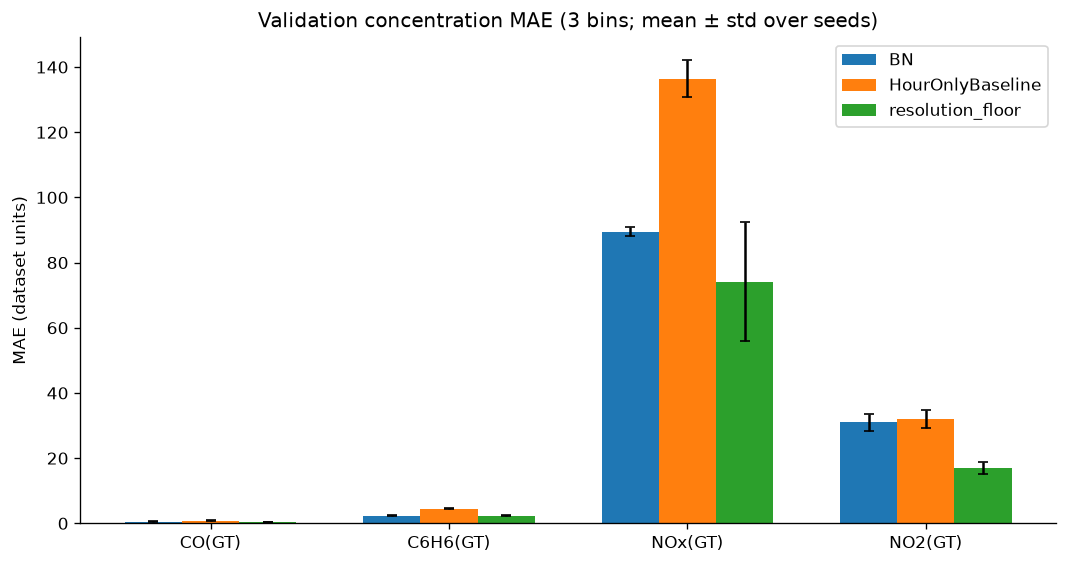

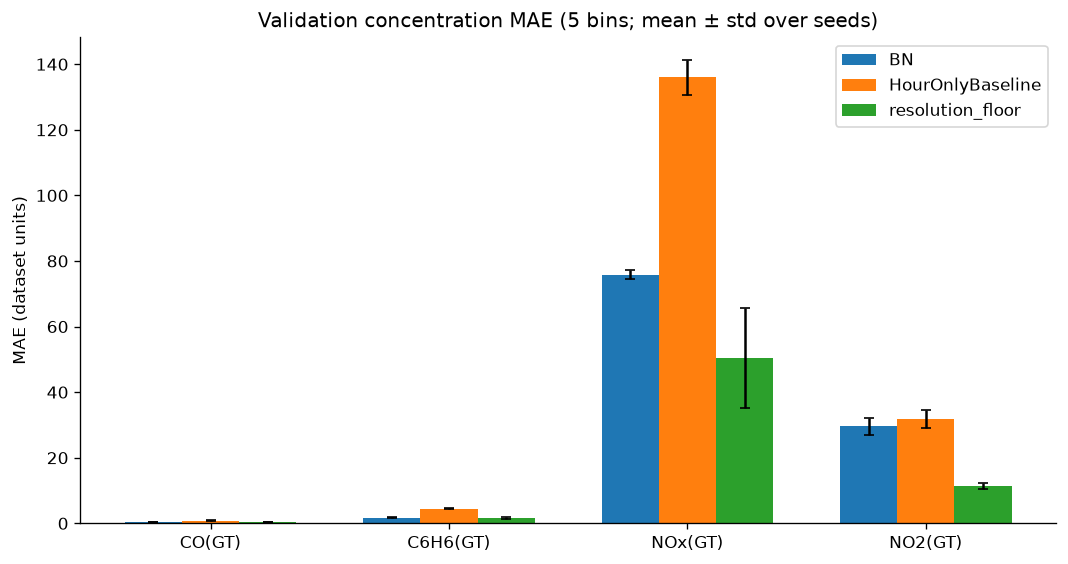

In [11]:
# Figure 1: MAE by gas and model for each bin count.
for n_bins in BIN_COUNTS:
    plot_data = concentration_summary[concentration_summary["bins"] == n_bins]
    gases_order = [str(g) for g in GASES]
    models_order = ["BN", "HourOnlyBaseline", "resolution_floor"]
    x = np.arange(len(gases_order))
    width = 0.24
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for j, model_name in enumerate(models_order):
        sub = plot_data[plot_data["model"] == model_name].set_index("gas").reindex(gases_order)
        ax.bar(
            x + (j - 1) * width,
            sub["MAE_mean"],
            width,
            yerr=sub["MAE_std"],
            capsize=3,
            label=model_name,
        )
    ax.set_xticks(x, gases_order)
    ax.set_ylabel("MAE (dataset units)")
    ax.set_title(f"Validation concentration MAE ({n_bins} bins; mean ± std over seeds)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f"concentration_mae_{n_bins}bins.png", bbox_inches="tight")
    plt.show()

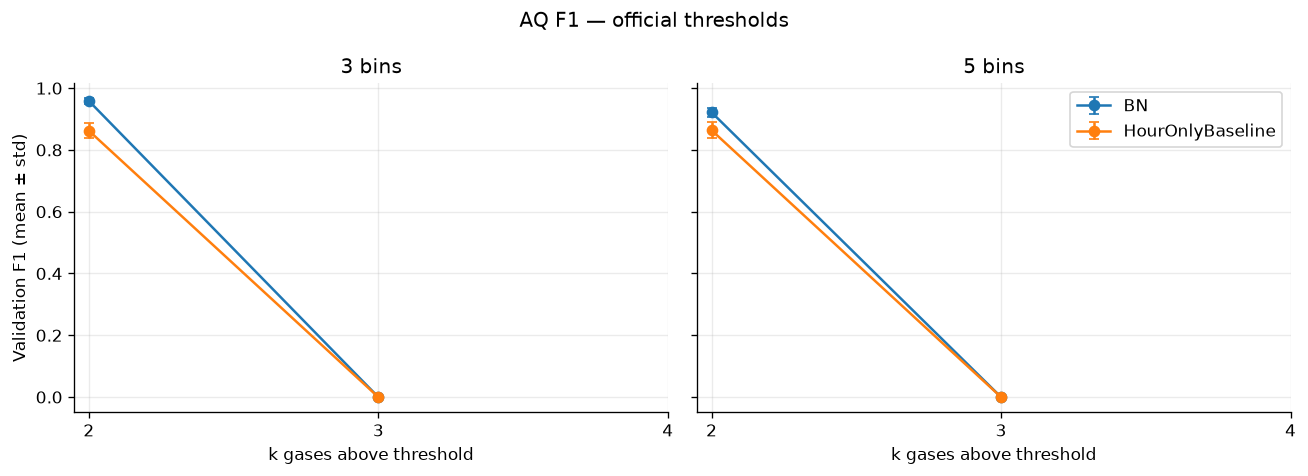

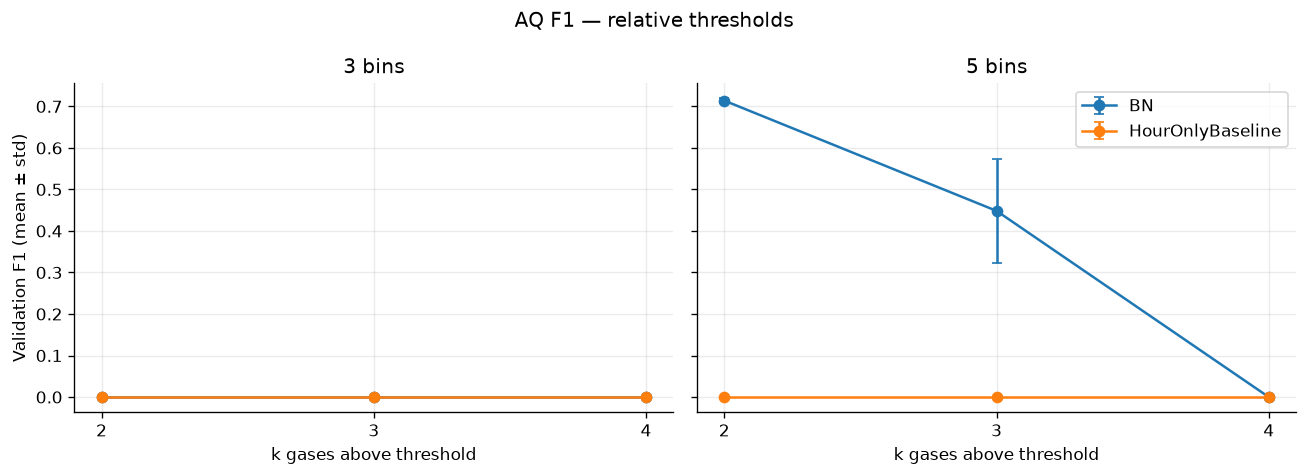

In [12]:
# Figure 2: BN vs HourOnlyBaseline AQ F1 across k, split by threshold family and bins.
for threshold_name in ("official", "relative"):
    fig, axes = plt.subplots(1, len(BIN_COUNTS), figsize=(11, 4), sharey=True)
    if len(BIN_COUNTS) == 1:
        axes = [axes]
    for ax, n_bins in zip(axes, BIN_COUNTS):
        sub = aq_summary[
            (aq_summary["threshold"] == threshold_name)
            & (aq_summary["bins"] == n_bins)
        ]
        for model_name in ("BN", "HourOnlyBaseline"):
            m = sub[sub["model"] == model_name].set_index("k").reindex(K_VALUES)
            ax.errorbar(K_VALUES, m["F1_mean"], yerr=m["F1_std"], marker="o", capsize=3, label=model_name)
        ax.set_xticks(K_VALUES)
        ax.set_xlabel("k gases above threshold")
        ax.set_title(f"{n_bins} bins")
        ax.grid(alpha=0.25)
    axes[0].set_ylabel("Validation F1 (mean ± std)")
    axes[-1].legend()
    fig.suptitle(f"AQ F1 — {threshold_name} thresholds")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f"aq_f1_{threshold_name}.png", bbox_inches="tight")
    plt.show()

**9. Inspect false-negative bad hours and the top-bin cap**

The expected-concentration estimatior is bounded above by the largest training bin mean. Consequently, reference spikes above that value cannot be reconstructed exactly. The table below checks whether false-negative AQ hours contain one or more reference readings above the corresponding gas' top-bin mean.

In [13]:
val_raw = chosen["val_raw"]
bn_est = chosen["bn_est"]
aq_true = air_quality(val_raw, chosen_thresholds, k=CHOSEN_K)
aq_bn = air_quality(bn_est, chosen_thresholds, k=CHOSEN_K)
false_negative_mask = (aq_true == 1) & (aq_bn == 0)

spike_above_cap = pd.Series(False, index=val_raw.index)
spike_gases = []
for idx in val_raw.index[false_negative_mask.fillna(False)]:
    exceeded = [
        str(g) for g in GASES
        if pd.notna(val_raw.at[idx, g])
        and val_raw.at[idx, g] > float(chosen["c_bar"][g].max())
    ]
    spike_gases.append({"timestamp": idx, "gases_above_top_bin_mean": ", ".join(exceeded) or "none"})
    spike_above_cap.loc[idx] = bool(exceeded)

false_negative_spikes = pd.DataFrame(spike_gases)
print("False-negative bad hours:", int(false_negative_mask.sum()))
print("False negatives with at least one reference above its top-bin mean:",
      int(spike_above_cap[false_negative_mask.fillna(False)].sum()))
false_negative_spikes.head(30)

False-negative bad hours: 99
False negatives with at least one reference above its top-bin mean: 4


,timestamp,gases_above_top_bin_mean
0,2004-03-26 00:00:00,none
1,2004-03-26 15:00:00,none
2,2004-03-27 00:00:00,none
3,2004-03-28 04:00:00,none
4,2004-03-28 13:00:00,none
5,2004-03-29 09:00:00,none
6,2004-03-29 10:00:00,none
7,2004-03-29 12:00:00,none
8,2004-03-29 14:00:00,none
9,2004-03-29 15:00:00,none


In [14]:
# Save the selected validation estimates and diagnostic false-negative list.
chosen_val_estimates = chosen["bn_est"].copy()
chosen_val_estimates["AQ_reference"] = aq_true
chosen_val_estimates["AQ_BN"] = aq_bn
chosen_val_estimates.to_csv(
    RESULT_DIR / f"estimates_val_bins{CHOSEN_BINS}_seed{CHOSEN_SEED}.csv",
    index_label="datetime",
)
false_negative_spikes.to_csv(RESULT_DIR / "false_negative_spikes_val.csv", index=False)

**10. Final test evaluation - selected configuration only**

The selected discretizer and fitted models are reused from the chosen (bins, seed) run. No test labels or test metrics were used for selection. Each model predicts each gas once on the test split, and the AQ metrics are then computed for the chosen threshold family and k.

In [15]:
test_raw = chosen["test_raw"]
test_binned = chosen["test"]
test_c_bar = chosen["c_bar"]
test_thresholds = chosen["thresholds"][CHOSEN_THRESHOLD]
bn = model_cache[(CHOSEN_BINS, CHOSEN_SEED)]["bn"]
hour = model_cache[(CHOSEN_BINS, CHOSEN_SEED)]["hour"]

# Exactly one set of four gas predictions per model on test.
test_bn_est, test_bn_proba = estimate_all(bn, test_binned, test_c_bar)
test_hour_est, test_hour_proba = estimate_all(hour, test_binned, test_c_bar)

test_concentration_rows = []
for gas in GASES:
    for model_name, estimates in (("BN", test_bn_est), ("HourOnlyBaseline", test_hour_est)):
        test_concentration_rows.append({
            "gas": str(gas), "model": model_name,
            **concentration_error(estimates[gas], test_raw[gas]),
        })
    test_concentration_rows.append({
        "gas": str(gas), "model": "resolution_floor",
        **resolution_floor(test_raw[gas], test_binned[gas], test_c_bar[gas]),
    })
test_concentration = pd.DataFrame(test_concentration_rows)
test_concentration

,gas,model,n,MAE,RMSE
0,CO(GT),BN,1762,0.647948,1.010456
1,CO(GT),HourOnlyBaseline,1762,0.971160,1.382645
2,CO(GT),resolution_floor,1762,0.544002,0.915595
3,C6H6(GT),BN,2342,2.609804,4.319655
4,C6H6(GT),HourOnlyBaseline,2342,4.812035,6.744672
5,C6H6(GT),resolution_floor,2342,2.638800,4.336037
6,NOx(GT),BN,1806,115.792745,179.536294
7,NOx(GT),HourOnlyBaseline,1806,160.023021,228.193484
8,NOx(GT),resolution_floor,1806,85.467479,149.993487
9,NO2(GT),BN,1805,32.459446,41.986781


In [16]:
test_aq_true = air_quality(test_raw, test_thresholds, k=CHOSEN_K)
test_aq_bn = air_quality(test_bn_est, test_thresholds, k=CHOSEN_K)
test_aq_hour = air_quality(test_hour_est, test_thresholds, k=CHOSEN_K)

test_aq = pd.DataFrame([
    {"model": "BN", **binary_metrics(test_aq_true, test_aq_bn)},
    {"model": "HourOnlyBaseline", **binary_metrics(test_aq_true, test_aq_hour)},
])
test_aq

,model,n,bad_rate,predicted_bad_rate,recall,precision,F1,accuracy,TN,FP,FN,TP
0,BN,1693,0.759008,0.721205,0.948638,0.998362,0.972865,0.959835,406,2,66,1219
1,HourOnlyBaseline,1693,0.759008,0.883048,0.962646,0.827425,0.889928,0.819256,150,258,48,1237


In [17]:
test_bn_est["AQ_reference"] = test_aq_true
test_bn_est["AQ_BN"] = test_aq_bn
test_bn_est["AQ_HourOnlyBaseline"] = test_aq_hour
test_bn_est.to_csv(RESULT_DIR / "estimates_test_selected.csv", index_label="datetime")
test_concentration.to_csv(RESULT_DIR / "concentration_test_selected.csv", index=False)
test_aq.to_csv(RESULT_DIR / "aq_test_selected.csv", index=False)

**11. Save a Phase 3a decision record**

This cell prints the decision entry to add to docs/decision.md. Set  WRITE_DECISION = True only after reviewing the validation tables and confirming the threshold-unit mapping.

In [18]:
WRITE_DECISION = False  # Change to True after team review.

decision_line = (
    f"- 2026-11-10 — Phase 3a concentration/AQ evaluation — "
    f"selected {CHOSEN_BINS} bins, {CHOSEN_THRESHOLD} thresholds, and k={CHOSEN_K} "
    f"using validation BN F1 (mean={best_row['F1_mean']:.3f}); "
    f"representative seed={CHOSEN_SEED}. Official thresholds are retained as a "
    f"standards-context comparison; dataset-relative thresholds define the "
    f"informative hourly AQ experiment. Review unit and averaging-period caveats."
)
print(decision_line)

if WRITE_DECISION:
    decision_path = Path("docs/decisions.md")
    with decision_path.open("a", encoding="utf-8") as f:
        f.write("\n" + decision_line + "\n")
    print("Appended to", decision_path)

- 2026-11-10 — Phase 3a concentration/AQ evaluation — selected 3 bins, official thresholds, and k=2 using validation BN F1 (mean=0.959); representative seed=2. Official thresholds are retained as a standards-context comparison; dataset-relative thresholds define the informative hourly AQ experiment. Review unit and averaging-period caveats.


**12. Interpretation and limitations**

Use the tables above to complete the project report. In particular, state:
1. Whether BN MAE beats the hour-only baseline for each gas, and how close each model is to the resolution floor.
2. How often reference AQ is bad under official versus relative thresholds. Official standards have different averaging periods, so hourly thresholding is only an approximate diagnostic.
3. Whether BN recall/precision/F1 improve on the hour-only baseline for each k.
4. Whether false-negative bad hours include reference spikes above the top-bin mean.
5. The selected thresholds, k, and bin count, and why the validation results support that choice.

Limitations to Report
* This rule on point estimates retursn one yes/no label per hour; it does not estimate P(AQ = bad)
* It ignores the joint dependence among gases when several concentrations are uncertain simultaneously. Four marginal expected concentrations do not preserved cross-gas posterior co-movement
* The estimate cannot exceed a gas' largest training-bin mean, so extreme spikes are systematically underestimated and some true bad hours can be missed.
* The official limits do not all describe one-hour averages. In particular, applying annual or 8-hour limits to hourly readinsg is not a regulartory AQI calculation.
* The Phase 2 network is a static same-four model; it does not use temporal transitions between adjacent hours.
